In [1]:
import pandas as pd

user_features = pd.read_csv(
    "../data/processed/user_features.csv",
    index_col=0
)

user_features.head()

,total_orders,avg_days_between_orders,reorder_ratio
user_id,,,
1,11,19.000000,0.694915
2,15,16.285714,0.476923
3,13,12.000000,0.625000
4,6,17.000000,0.055556
5,5,11.500000,0.378378


In [2]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(user_features)

scaled_features[:5]

array([[-0.33566236,  0.51352523,  1.23815226],
       [-0.0954904 ,  0.12103549,  0.21058293],
       [-0.21557638, -0.49868517,  0.90858644],
       [-0.63587732,  0.22432226, -1.77565504],
       [-0.69592031, -0.57098591, -0.25393607]])

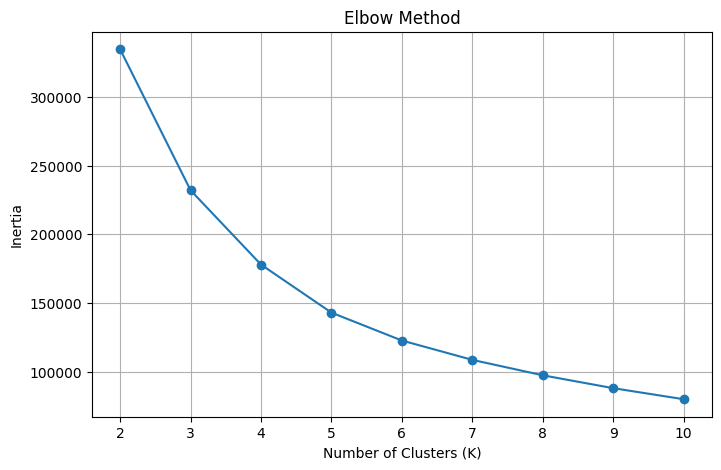

In [3]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42
    )

    kmeans.fit(scaled_features)

    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))

plt.plot(K_range, inertia, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.grid(True)

plt.show()

In [9]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42
)

clusters = kmeans.fit_predict(
    scaled_features
)

user_features["cluster"] = clusters

user_features.head()

,total_orders,avg_days_between_orders,reorder_ratio,cluster
user_id,,,,
1,11,19.000000,0.694915,0
2,15,16.285714,0.476923,0
3,13,12.000000,0.625000,2
4,6,17.000000,0.055556,1
5,5,11.500000,0.378378,4


In [10]:
cluster_summary = user_features.groupby(
    "cluster"
).mean()

cluster_summary

,total_orders,avg_days_between_orders,reorder_ratio
cluster,,,
0,11.045826,19.374172,0.506386
1,6.014327,23.748862,0.211630
2,24.677046,10.211204,0.625155
3,62.928502,5.742290,0.734701
4,9.134487,11.748567,0.284209


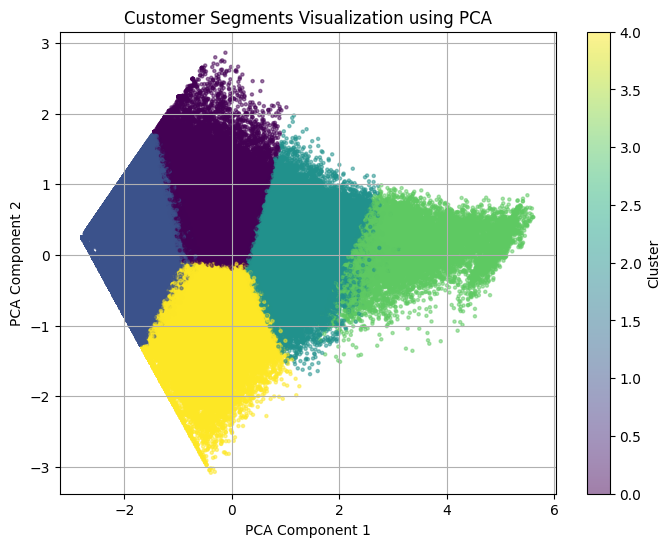

In [11]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
pca_features = pca.fit_transform(scaled_features)

plt.figure(figsize=(8, 6))
plt.scatter(
    pca_features[:, 0],
    pca_features[:, 1],
    c=user_features["cluster"],
    s=5,
    alpha=0.5
)

plt.title("Customer Segments Visualization using PCA")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

In [12]:
cluster_summary = user_features.groupby("cluster").mean()
cluster_summary

,total_orders,avg_days_between_orders,reorder_ratio
cluster,,,
0,11.045826,19.374172,0.506386
1,6.014327,23.748862,0.211630
2,24.677046,10.211204,0.625155
3,62.928502,5.742290,0.734701
4,9.134487,11.748567,0.284209


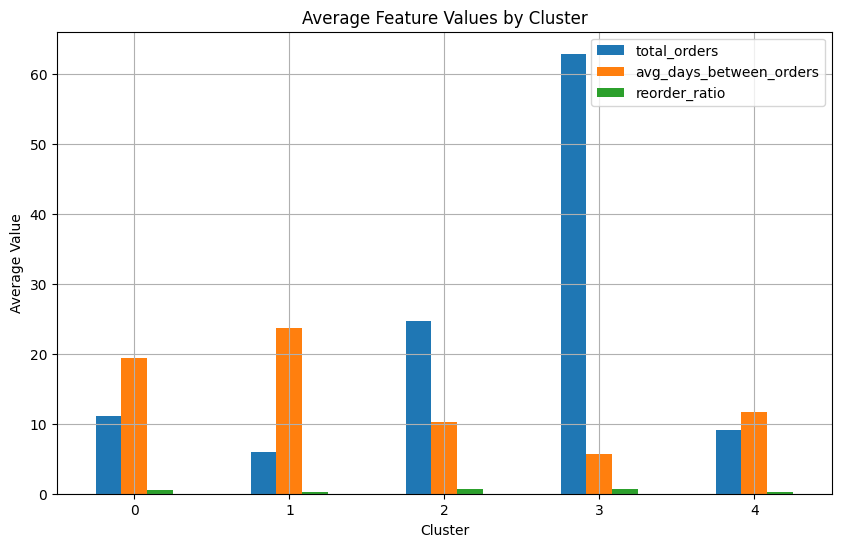

In [13]:
cluster_summary.plot(kind="bar", figsize=(10, 6))

plt.title("Average Feature Values by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.grid(True)
plt.show()

In [14]:
user_features.to_csv(
    "../data/processed/user_clusters.csv"
)

In [15]:
# Count number of users in each cluster
cluster_counts = user_features['cluster'].value_counts().sort_index()

# Convert to DataFrame
cluster_summary = cluster_counts.reset_index()
cluster_summary.columns = ['cluster', 'num_users']

# Add percentage
cluster_summary['percentage'] = (
    cluster_summary['num_users'] / cluster_summary['num_users'].sum() * 100
).round(2)

cluster_summary

,cluster,num_users,percentage
0,0,46196,22.40
1,1,48300,23.42
2,2,49202,23.86
3,3,15525,7.53
4,4,46986,22.79


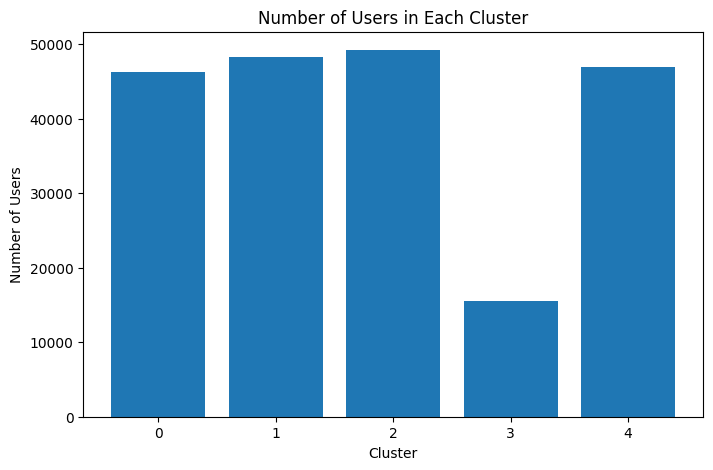

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(cluster_summary['cluster'], cluster_summary['num_users'])
plt.xlabel('Cluster')
plt.ylabel('Number of Users')
plt.title('Number of Users in Each Cluster')
plt.xticks(cluster_summary['cluster'])
plt.show()